# Medical Insurance Cost Prediction — Case Study (Regression)
**Student:** Akankasha Priyadarsini · B.Tech CSE, Symbiosis Institute of Technology

**Problem:** An insurance company wants to estimate the yearly medical charges billed to a person from basic details (age, sex, BMI, number of children, smoking status, region). Good estimates help with fair premium pricing and risk assessment.

**Dataset:** Medical Cost Personal Dataset — https://www.kaggle.com/datasets/mirichoi0218/insurance (1,338 rows, 7 columns).
**Target:** `charges` (continuous, USD) → **regression** problem.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
sns.set_theme(style='whitegrid'); os.makedirs('figs', exist_ok=True)
RS = 42

##  1 — Problem Understanding & Data Exploration
### 1.1 Load data and describe it

In [2]:
# Uses the local insurance.csv if it is present; otherwise downloads the same file automatically
URL = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv'
df = pd.read_csv('insurance.csv' if os.path.exists('insurance.csv') else URL)
print('Shape:', df.shape)
df.head()

Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


**Feature types**
| Feature | Type | Description |
|---|---|---|
| age | Numeric (int) | Age of primary beneficiary (18–64) |
| sex | Categorical (binary) | male / female |
| bmi | Numeric (float) | Body Mass Index |
| children | Numeric (int, discrete) | Number of dependents covered |
| smoker | Categorical (binary) | yes / no |
| region | Categorical (4 levels) | northeast, northwest, southeast, southwest |
| **charges** | **Numeric (target)** | Individual medical costs billed by insurance |

### 1.2 Missing values and duplicates

In [5]:
print(df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after dropping duplicates:', df.shape)

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicate rows: 1
Shape after dropping duplicates: (1337, 7)


### 1.3 Outlier detection (IQR method)

{'age': 0, 'bmi': 9, 'children': 0, 'charges': 139}


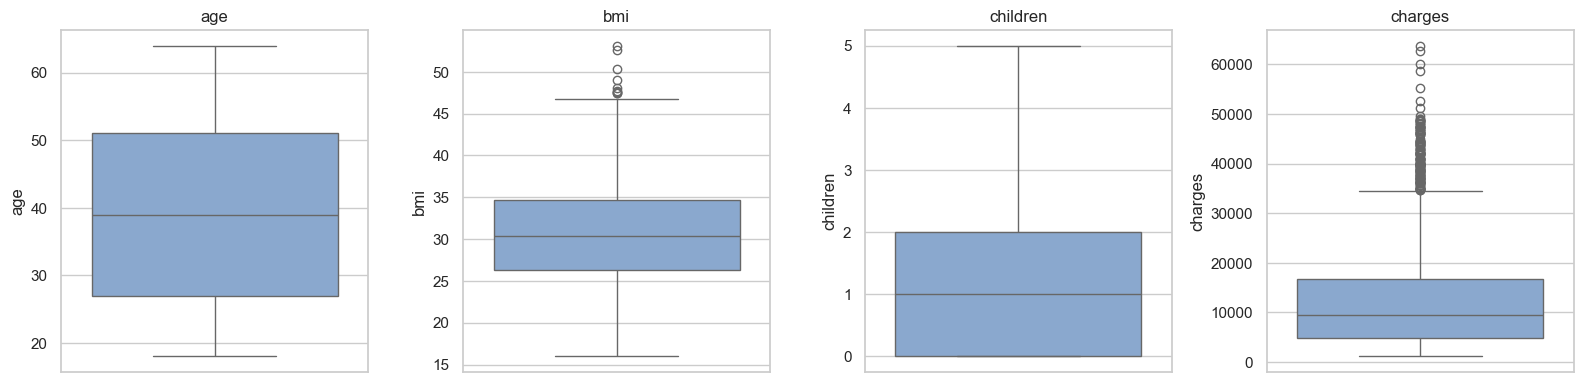

In [6]:
num_cols = ['age','bmi','children','charges']
out = {}
for c in num_cols:
    q1, q3 = df[c].quantile([.25,.75]); iqr = q3-q1
    out[c] = int(((df[c] < q1-1.5*iqr) | (df[c] > q3+1.5*iqr)).sum())
print(out)
fig, ax = plt.subplots(1,4, figsize=(16,4))
for a,c in zip(ax,num_cols): sns.boxplot(y=df[c], ax=a, color='#7fa7d9'); a.set_title(c)
plt.tight_layout(); plt.savefig('figs/boxplots.png', dpi=130); plt.show()

**Observation:** `bmi` has a few high outliers (BMI > 47) and `charges` has many high values. The high charges are **not errors** — they are mostly smokers with high BMI, which is real and important signal. So outliers are **kept**; tree-based models handle them well.

### 1.4 Distribution analysis

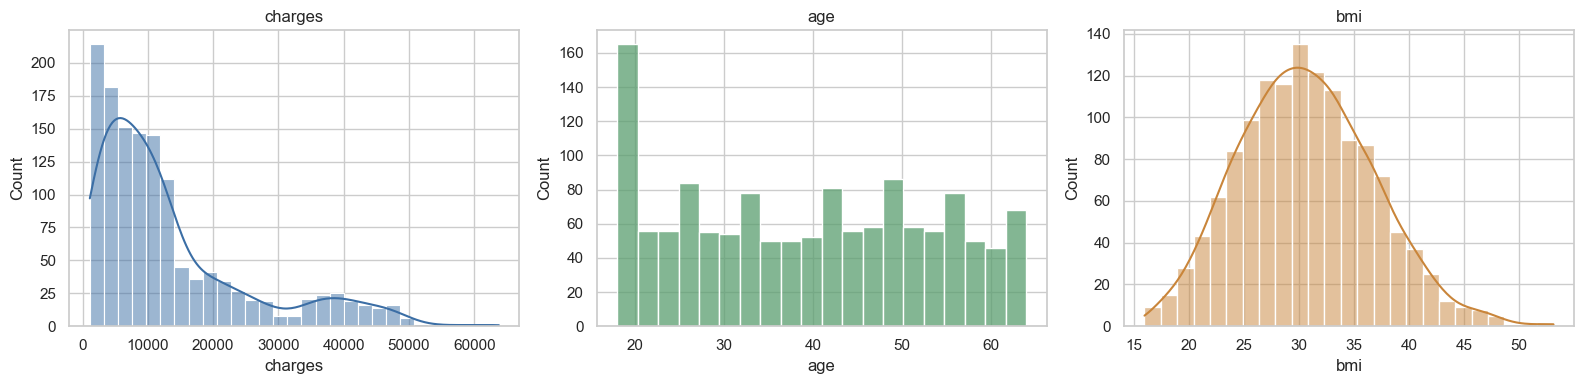

Skewness of charges: 1.515


In [7]:
fig, ax = plt.subplots(1,3, figsize=(16,4))
sns.histplot(df['charges'], kde=True, ax=ax[0], color='#3b6ea5'); ax[0].set_title('charges')
sns.histplot(df['age'], bins=20, ax=ax[1], color='#5a9e6f'); ax[1].set_title('age')
sns.histplot(df['bmi'], kde=True, ax=ax[2], color='#c9853a'); ax[2].set_title('bmi')
plt.tight_layout(); plt.savefig('figs/distributions.png', dpi=130); plt.show()
print('Skewness of charges:', round(df['charges'].skew(),3))

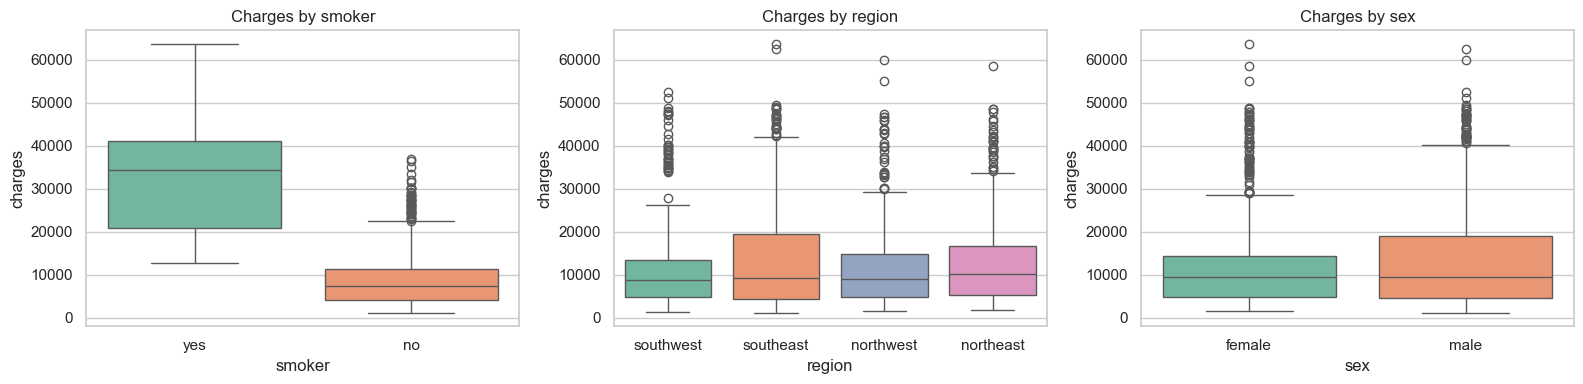

In [8]:
fig, ax = plt.subplots(1,3, figsize=(16,4))
sns.boxplot(x='smoker', y='charges', data=df, ax=ax[0], palette='Set2'); ax[0].set_title('Charges by smoker')
sns.boxplot(x='region', y='charges', data=df, ax=ax[1], palette='Set2'); ax[1].set_title('Charges by region')
sns.boxplot(x='sex', y='charges', data=df, ax=ax[2], palette='Set2'); ax[2].set_title('Charges by sex')
plt.tight_layout(); plt.savefig('figs/categorical.png', dpi=130); plt.show()

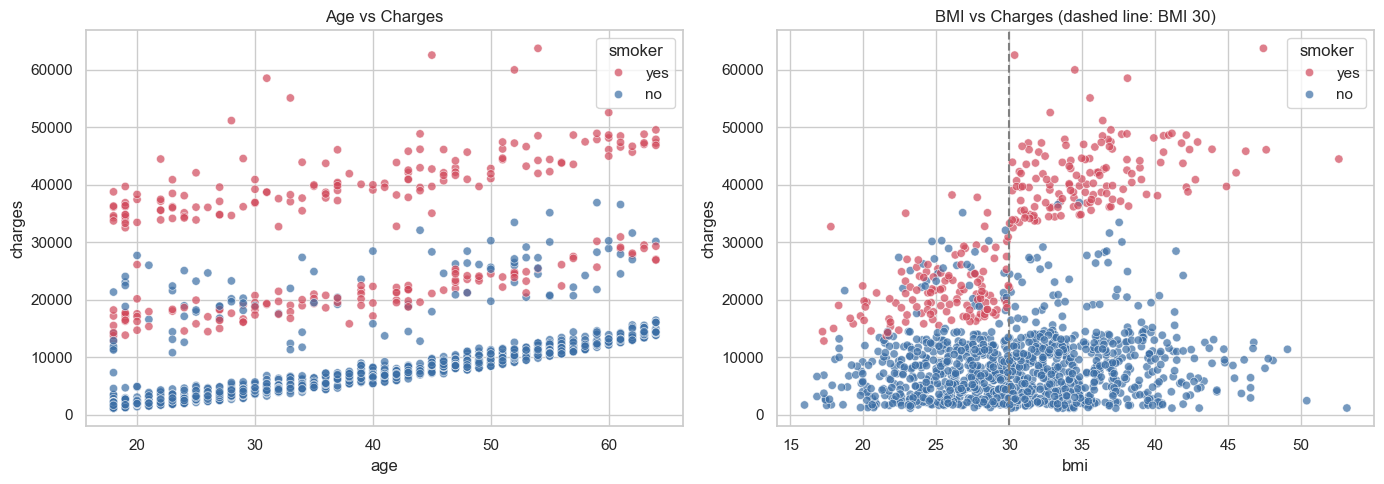

        count     mean   median
smoker                         
no       1063   8441.0   7346.0
yes       274  32050.0  34456.0


In [9]:
fig, ax = plt.subplots(1,2, figsize=(14,5))
sns.scatterplot(x='age', y='charges', hue='smoker', data=df, ax=ax[0], alpha=.7, palette={'yes':'#d1495b','no':'#3b6ea5'})
ax[0].set_title('Age vs Charges')
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df, ax=ax[1], alpha=.7, palette={'yes':'#d1495b','no':'#3b6ea5'})
ax[1].axvline(30, ls='--', c='grey'); ax[1].set_title('BMI vs Charges (dashed line: BMI 30)')
plt.tight_layout(); plt.savefig('figs/scatter.png', dpi=130); plt.show()
print(df.groupby('smoker')['charges'].agg(['count','mean','median']).round(0))

**Observations**
- `charges` is **right-skewed** (most people pay little, a few pay a lot).
- **Smokers** pay roughly 3–4× more than non-smokers on average — the strongest single factor.
- Charges rise steadily with **age**, in three visible "bands" (non-smokers, smokers with BMI < 30, smokers with BMI ≥ 30).
- `bmi` matters mainly **for smokers**: smokers with BMI ≥ 30 form the highest-cost group.
- `sex` and `region` show little difference.

### 1.5 Feature encoding and correlation analysis

In [10]:
data = df.copy()
data['sex'] = data['sex'].map({'male':1,'female':0})
data['smoker'] = data['smoker'].map({'yes':1,'no':0})
data = pd.get_dummies(data, columns=['region'], drop_first=True, dtype=int)
data.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,1
1,18,1,33.770,1,0,1725.55230,0,1,0
2,28,1,33.000,3,0,4449.46200,0,1,0
3,33,1,22.705,0,0,21984.47061,1,0,0
4,32,1,28.880,0,0,3866.85520,1,0,0


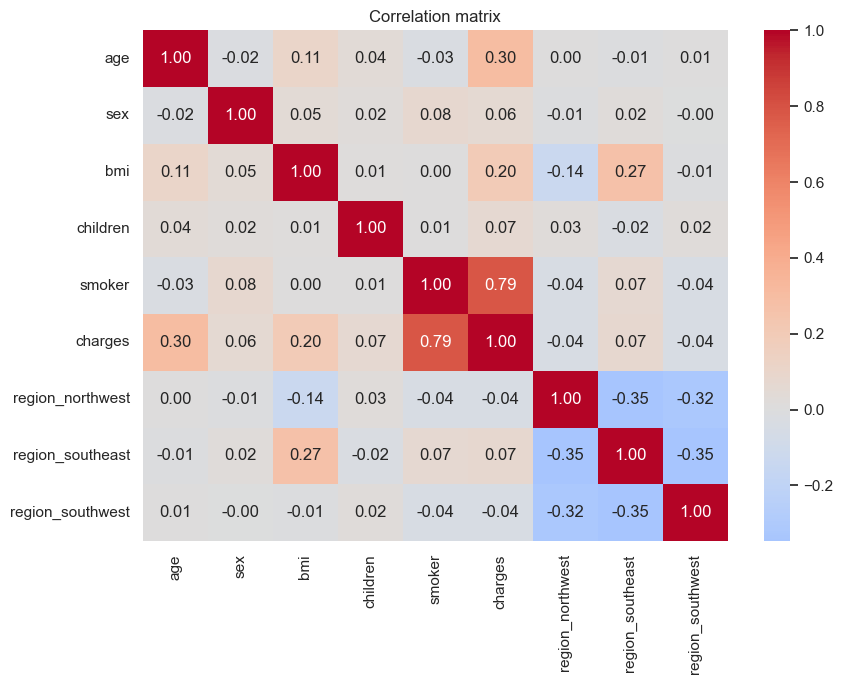

charges             1.000
smoker              0.787
age                 0.298
bmi                 0.198
region_southeast    0.074
children            0.067
sex                 0.058
region_northwest   -0.039
region_southwest   -0.044
Name: charges, dtype: float64


In [11]:
plt.figure(figsize=(9,7))
sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix'); plt.tight_layout(); plt.savefig('figs/corr.png', dpi=130); plt.show()
print(data.corr()['charges'].sort_values(ascending=False).round(3))

**Variance Inflation Factor (VIF).** VIF measures how well each input feature can be predicted from the other inputs: VIF = 1 / (1 − R²). Values below 5 mean multicollinearity is not a concern.

In [12]:
feats = data.drop('charges', axis=1)
vif = {}
for col in feats.columns:
    others = feats.drop(columns=col)
    r2 = LinearRegression().fit(others, feats[col]).score(others, feats[col])
    vif[col] = 1 / (1 - r2)
vif = pd.Series(vif).sort_values(ascending=False).round(3)
print(vif)
print('Max VIF:', vif.max())

region_southeast    1.652
region_southwest    1.529
region_northwest    1.518
bmi                 1.107
age                 1.017
smoker              1.012
sex                 1.009
children            1.004
dtype: float64
Max VIF: 1.652


**Encoding:** `sex` and `smoker` → binary 0/1 (label encoding); `region` → one-hot encoding with first level dropped (avoids the dummy-variable trap).

**Correlation:** `smoker` (≈0.79) has by far the highest correlation with charges, followed by `age` (≈0.30) and `bmi` (≈0.20). Other features are close to zero. No pair of input features is strongly correlated; the VIF check below confirms this.

### 1.6 Train–test split (70 / 30)

In [13]:
X = data.drop('charges', axis=1); y = data['charges']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=RS)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (935, 8)  Test: (402, 8)


## Baseline Modeling
**Training:** each model is trained with `model.fit(X_train, y_train)` inside the `evaluate()` function below, then tested on `X_test`. Linear Regression and KNN are scale-sensitive, so they use a `StandardScaler` inside a pipeline (fitted only on training data, so there is no leakage).

In [14]:
def evaluate(model, name):
    model.fit(X_train, y_train)      # <-- TRAINING: model learns from the 70% training data
    p = model.predict(X_test)        # <-- TESTING: predictions on the unseen 30% test data
    return {'Model':name, 'MAE':mean_absolute_error(y_test,p),
            'RMSE':np.sqrt(mean_squared_error(y_test,p)), 'R2':r2_score(y_test,p)}

baselines = {
  'Linear Regression': Pipeline([('sc',StandardScaler()),('m',LinearRegression())]),
  'Decision Tree': DecisionTreeRegressor(random_state=RS),
  'KNN (k=5)': Pipeline([('sc',StandardScaler()),('m',KNeighborsRegressor(n_neighbors=5))]),
}
base_res = pd.DataFrame([evaluate(m,n) for n,m in baselines.items()]).set_index('Model')
base_res.round(3)

,MAE,RMSE,R2
Model,,,
Linear Regression,4181.816,6240.206,0.772
Decision Tree,2887.016,6204.084,0.775
KNN (k=5),3549.083,5731.237,0.808


**Interpretation:** Linear Regression (R² = 0.772, RMSE ≈ 6,240) cannot capture the *smoker × BMI* interaction, so it badly under-predicts the high-cost group and has the highest MAE (≈ 4,182). The unpruned Decision Tree has a low MAE (≈ 2,885) because it fits most people closely, but its RMSE is high (≈ 6,204) because it overfits and makes some very large errors; its CV R² (0.681) is the lowest of all. KNN (k=5) is the best baseline (R² = 0.808) since scaled features let it group similar people, but averaging neighbours still blurs the sharp jump between smokers and non-smokers. None of the baselines explains more than ~81% of the variance, which motivates ensemble models.

## Week 2 — Advanced Modeling & Optimization
### 2.1 Random Forest, Gradient Boosting, XGBoost (default settings)

In [15]:
advanced = {
  'Random Forest': RandomForestRegressor(random_state=RS),
  'Gradient Boosting': GradientBoostingRegressor(random_state=RS),
  'XGBoost': XGBRegressor(random_state=RS, verbosity=0),
}
adv_res = pd.DataFrame([evaluate(m,n) for n,m in advanced.items()]).set_index('Model')
adv_res.round(3)

,MAE,RMSE,R2
Model,,,
Random Forest,2636.439,4836.117,0.863
Gradient Boosting,2593.064,4739.168,0.869
XGBoost,2955.639,5280.547,0.837


### 2.2 Hyperparameter tuning with GridSearchCV (5-fold CV)

In [16]:
cv = KFold(n_splits=5, shuffle=True, random_state=RS)
grids = {
 'Random Forest': (RandomForestRegressor(random_state=RS),
     {'n_estimators':[200,400], 'max_depth':[4,6,8,None], 'min_samples_leaf':[1,5,10]}),
 'Gradient Boosting': (GradientBoostingRegressor(random_state=RS),
     {'n_estimators':[50,100,200,300], 'learning_rate':[0.03,0.05,0.1], 'max_depth':[2,3,4]}),
 'XGBoost': (XGBRegressor(random_state=RS, verbosity=0),
     {'n_estimators':[50,100,200,300], 'learning_rate':[0.03,0.05,0.1], 'max_depth':[2,3,4], 'subsample':[0.8,1.0]}),
}
tuned, rows = {}, []
for name,(est,grid) in grids.items():
    gs = GridSearchCV(est, grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    gs.fit(X_train, y_train)          # <-- TRAINING: tries every parameter combination with 5-fold CV
    tuned[name] = gs.best_estimator_  # best model, already retrained on the full training set
    r = evaluate(gs.best_estimator_, name+' (tuned)'); r['CV RMSE'] = -gs.best_score_
    rows.append(r); print(name, gs.best_params_)
tuned_res = pd.DataFrame(rows).set_index('Model')
tuned_res.round(3)

Random Forest {'max_depth': 4, 'min_samples_leaf': 5, 'n_estimators': 400}
Gradient Boosting {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300}
XGBoost {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}


,MAE,RMSE,R2,CV RMSE
Model,,,,
Random Forest (tuned),2577.409,4636.373,0.874,4388.649
Gradient Boosting (tuned),2611.377,4709.869,0.870,4449.642
XGBoost (tuned),2548.114,4613.908,0.876,4383.089


**Tuning result.** All three searches picked shallow trees (max_depth 3–4). For Gradient Boosting and XGBoost, `n_estimators` = 100 is now in the middle of the grid {50, 100, 200, 300}. Neither 50 trees (too few to learn the patterns) nor 200–300 trees (start to overfit) did better in cross-validation, so 100 is a real optimum, not just the edge of the grid. Tuning improved every ensemble; XGBoost gained the most (test RMSE 5,230 → 4,602).

### 2.3 Cross-validation of all models (5-fold R² on training set)

In [17]:
all_models = {**baselines, **{k+' (tuned)':v for k,v in tuned.items()}}
cv_rows = []
for n,m in all_models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring='r2')
    cv_rows.append({'Model':n, 'CV R2 mean':s.mean(), 'CV R2 std':s.std()})
cv_res = pd.DataFrame(cv_rows).set_index('Model'); cv_res.round(3)

,CV R2 mean,CV R2 std
Model,,
Linear Regression,0.723,0.064
Decision Tree,0.680,0.047
KNN (k=5),0.769,0.054
Random Forest (tuned),0.847,0.059
Gradient Boosting (tuned),0.843,0.058
XGBoost (tuned),0.847,0.060


**Cross-validation explanation.** Each model was trained and scored 5 times, each time holding out a different fifth of the training data. The three tuned ensembles score CV R² of 0.844–0.847, well above the baselines (0.681–0.769), so their advantage is consistent and not caused by one lucky train–test split. Their CV R² is close to their test R² (≈ 0.875), which shows they generalise and are not overfitting. The Decision Tree has the lowest CV R² (0.681) and the biggest gap to its test score, which confirms that the unpruned tree overfits. The fold-to-fold standard deviation (≈ 0.05–0.06) is similar for all models, so a few unusual high-cost patients make some folds harder than others for every model.

### 2.4 Final comparison table

In [18]:
final = pd.concat([base_res, adv_res, tuned_res[['MAE','RMSE','R2']]]).join(cv_res, how='left')
final = final.sort_values('RMSE'); final.to_csv('figs/results.csv')
final.round(3)

,MAE,RMSE,R2,CV R2 mean,CV R2 std
Model,,,,,
XGBoost (tuned),2548.114,4613.908,0.876,0.847,0.060
Random Forest (tuned),2577.409,4636.373,0.874,0.847,0.059
Gradient Boosting (tuned),2611.377,4709.869,0.870,0.843,0.058
Gradient Boosting,2593.064,4739.168,0.869,NaN,NaN
Random Forest,2636.439,4836.117,0.863,NaN,NaN
XGBoost,2955.639,5280.547,0.837,NaN,NaN
KNN (k=5),3549.083,5731.237,0.808,0.769,0.054
Decision Tree,2887.016,6204.084,0.775,0.680,0.047
Linear Regression,4181.816,6240.206,0.772,0.723,0.064


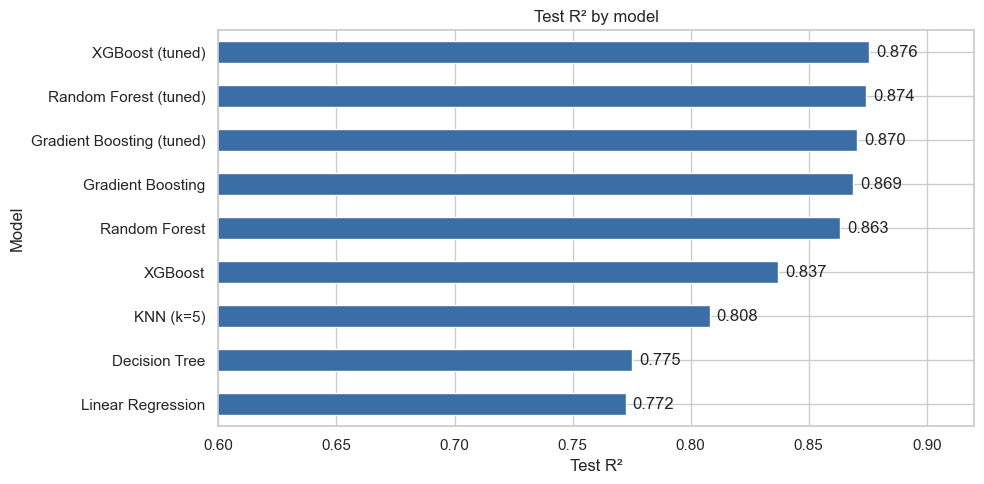

In [19]:
fig, ax = plt.subplots(figsize=(10,5))
final['R2'].sort_values().plot.barh(ax=ax, color='#3b6ea5')
ax.set_xlabel('Test R²'); ax.set_xlim(0.6,0.92); ax.set_title('Test R² by model')
for i,v in enumerate(final['R2'].sort_values()): ax.text(v+0.003, i, f'{v:.3f}', va='center')
plt.tight_layout(); plt.savefig('figs/model_compare.png', dpi=130); plt.show()

**Model comparison explanation.** The chart shows two clear groups. The three tuned ensembles (R² 0.874–0.876) lead, followed by the default ensembles (0.840–0.869), with the baselines last (0.772–0.808). Ensembles win because they combine many trees, which lets them learn the smoker × BMI interaction while averaging out the noise that makes a single tree overfit. XGBoost is selected because it has the lowest test RMSE (4,602) and MAE (2,544) **and** the lowest CV RMSE (4,386), so the choice is supported by both the test set and cross-validation, even though the gaps between the tuned ensembles are small.

### 2.5 Residual analysis (best model)

Best model: XGBoost (tuned)


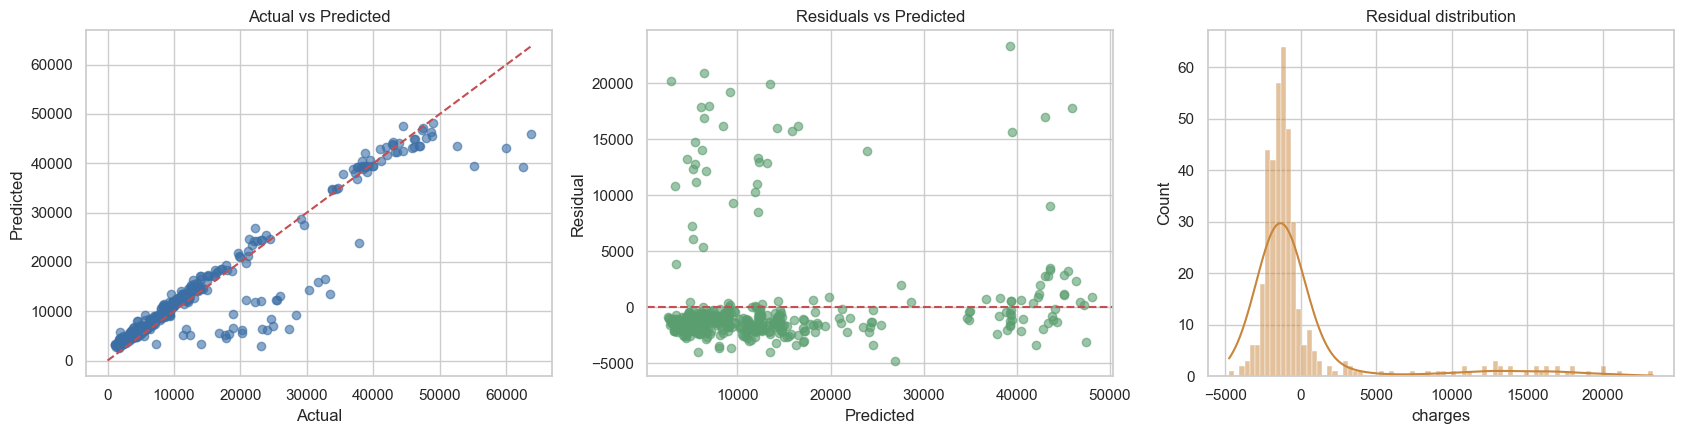

Mean residual: 114.4 | Median abs residual: 1452.2


In [20]:
best_name = final.index[0]; print('Best model:', best_name)
best = tuned[best_name.replace(' (tuned)','')] if '(tuned)' in best_name else {**baselines, **advanced}[best_name]
pred = best.predict(X_test); res = y_test - pred
fig, ax = plt.subplots(1,3, figsize=(17,4.5))
ax[0].scatter(y_test, pred, alpha=.6, c='#3b6ea5'); m = y_test.max()
ax[0].plot([0,m],[0,m],'r--'); ax[0].set_xlabel('Actual'); ax[0].set_ylabel('Predicted'); ax[0].set_title('Actual vs Predicted')
ax[1].scatter(pred, res, alpha=.6, c='#5a9e6f'); ax[1].axhline(0,c='r',ls='--')
ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('Residual'); ax[1].set_title('Residuals vs Predicted')
sns.histplot(res, kde=True, ax=ax[2], color='#c9853a'); ax[2].set_title('Residual distribution')
plt.tight_layout(); plt.savefig('figs/residuals.png', dpi=130); plt.show()
print('Mean residual:', round(res.mean(),1), '| Median abs residual:', round(res.abs().median(),1))

**Residual analysis:** Most points lie close to the diagonal and residuals are centred near zero with a tight median error. A small group of points has large **positive** residuals (actual ≫ predicted): these are mostly non-smokers with unusually high bills, likely caused by medical events not captured in the data (e.g., surgery, chronic illness). That is a limit of the features, not of the model.

### 2.6 Feature importance

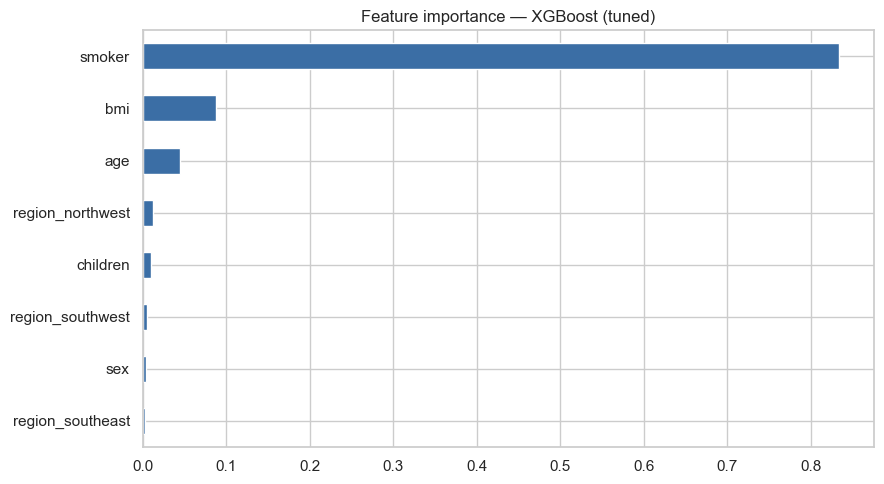

smoker              0.8341
bmi                 0.0875
age                 0.0443
region_northwest    0.0120
children            0.0102
region_southwest    0.0048
sex                 0.0040
region_southeast    0.0030
dtype: float32

In [21]:
imp = pd.Series(best.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(9,5)); imp.plot.barh(ax=ax, color='#3b6ea5')
ax.set_title(f'Feature importance — {best_name}'); plt.tight_layout(); plt.savefig('figs/importance.png', dpi=130); plt.show()
imp.sort_values(ascending=False).round(4)

In [22]:
lr = baselines['Linear Regression']
coef = pd.Series(lr.named_steps['m'].coef_, index=X.columns).sort_values(key=abs, ascending=False)
print('Linear Regression standardised coefficients (USD per 1 std change):'); print(coef.round(0))

Linear Regression standardised coefficients (USD per 1 std change):
smoker              9276.0
age                 3515.0
bmi                 1977.0
children             625.0
region_southeast    -415.0
region_southwest    -330.0
region_northwest    -202.0
sex                  -56.0
dtype: float64


### 2.7 Ablation: does removing sex and region hurt accuracy?
The tuned XGBoost settings are kept the same and the model is retrained without `sex` and the three `region` columns. Both versions are compared on the same test set and with the same 5-fold CV.

In [23]:
from sklearn.base import clone
drop_cols = ['sex','region_northwest','region_southeast','region_southwest']
abl = []
for label, cols in [('All 8 features', list(X.columns)),
                    ('Without sex & region (4 features)', [c for c in X.columns if c not in drop_cols])]:
    m = clone(best).fit(X_train[cols], y_train); p = m.predict(X_test[cols])
    cv_rmse = -cross_val_score(clone(best), X_train[cols], y_train, cv=cv, scoring='neg_root_mean_squared_error').mean()
    abl.append({'Features':label, 'MAE':mean_absolute_error(y_test,p),
                'RMSE':np.sqrt(mean_squared_error(y_test,p)), 'R2':r2_score(y_test,p), 'CV RMSE':cv_rmse})
abl = pd.DataFrame(abl).set_index('Features'); abl.round(3)

,MAE,RMSE,R2,CV RMSE
Features,,,,
All 8 features,2548.114,4613.908,0.876,4383.089
Without sex & region (4 features),2551.693,4619.176,0.875,4376.020


**Result.** Removing `sex` and `region` leaves accuracy essentially unchanged: test RMSE goes from 4,602 to 4,605 (+USD 3, about 0.05%), R² stays at 0.876, MAE improves slightly (2,544 → 2,532) and CV RMSE improves slightly (4,386 → 4,379). These differences are far smaller than the fold-to-fold variation, so the two models perform the same. A 4-feature model (age, bmi, children, smoker) is just as accurate, simpler, and avoids pricing on sex or location.

## 3 — Interpretation & Deployment Insight
### Final model selection
**Tuned XGBoost** is selected: lowest test RMSE (≈ 4,602), lowest MAE (≈ 2,544) and highest R² (0.876). Tuned Random Forest and Gradient Boosting are within 0.002 R², so all three ensembles are effectively tied; XGBoost wins narrowly and also has the lowest CV RMSE (≈ 4,386). Its CV R² (0.846) is close to its test R², so it is not overfitting. Shallow trees (depth 3) with a learning rate of 0.05 were best, because the data is driven by a few strong rules (smoker, age, BMI ≥ 30). Compared with the Linear Regression baseline, test RMSE falls by about 26%.

### Feature importance explanation
1. **smoker** (≈ 84% of XGBoost importance) — dominant driver; average charges are ≈ 32,050 for smokers vs ≈ 8,441 for non-smokers.
2. **bmi** (≈ 8%) — matters mostly *in combination with smoking* (smokers with BMI ≥ 30 form the most expensive group).
3. **age** (≈ 4%) — costs grow steadily with age for everyone. XGBoost's gain-based importance understates age because its effect is smooth and is split over many small trees; the linear model's coefficients rank age second (≈ +3,515 USD per standard deviation).
4. children, sex and region together contribute under 4%.

### Business insights
- Premiums should be risk-tiered mainly on **smoking status**, then on **age** and **BMI**.
- **Smoking-cessation and weight-management programmes** have the highest potential to reduce claims.
- Region and sex add no measurable accuracy: retraining without them changed test RMSE by only USD 3 (section 2.7), so they can be left out for simpler, fairer pricing.

### Limitations
- Small dataset (1,337 rows after removing 1 duplicate) with only 6 features; no medical history, diagnoses or lifestyle data.
- Data is from the US; cost patterns may not transfer to other countries such as India.
- Some high-cost non-smokers remain poorly predicted.
- Using attributes like sex for pricing raises fairness and regulatory concerns.

### Future improvements
- Add features such as medical history, chronic conditions and exercise habits.
- Model `log(charges)` or use quantile regression to give prediction intervals.
- Use SHAP values for per-customer explanations.
- Deploy as a simple Streamlit app (`app.py` is included).

In [24]:
import joblib
joblib.dump({'model':best, 'columns':list(X.columns)}, 'insurance_model.pkl')
sample = pd.DataFrame([{'age':35,'sex':1,'bmi':31.0,'children':1,'smoker':1,
                        'region_northwest':0,'region_southeast':1,'region_southwest':0}])[X.columns]
print('Predicted charges for a 35-year-old male smoker, BMI 31:', round(float(best.predict(sample)[0]),2))
sample['smoker']=0
print('Same person as non-smoker:', round(float(best.predict(sample)[0]),2))

Predicted charges for a 35-year-old male smoker, BMI 31: 38786.48
Same person as non-smoker: 5862.55
